# Gated diffusion: mixture model

Trial-level Bayesian fit, all animals pooled. Stimuli: `fast` (0.04 cpd, 8 Hz) and `slow` (0.16 cpd, 0.5 Hz).

- **Gate**: `q(c) = ceiling * (1 - exp(-c / scale))`, one `scale` per stimulus
- **Drift**: `v(c) = gain * c**2 / (c**2 + c50**2)`, shared by both stimuli
- **Lapse**: responses on gate-closed trials

Fitted: `gain`, `sigma`, `c50`, `scale_fast`, `scale_slow`. Fixed: `gamma = 2`, gate shapes `= 1`, `t0 = 50 ms`. Measured: `ceiling`, lapse probability, lapse timing.

In [9]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [10]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import torch

ROOT = Path(sys.executable).parents[2]
sys.path.insert(0, str(ROOT))
from modeling.data import load_trials, measure_constants
from modeling.fit import build_model, fit_trials, map_estimate
from modeling.model import GatedDiffusionMixture
from modeling.plots import gate_drift_figure, posterior_pairplot, predictive_figure

palette = {"fast": "#E08103", "slow": "#018EC6"}
plt.rcParams["font.family"] = "Helvetica"
np.random.seed(0)
torch.manual_seed(0)

### Trials

One session per animal. KC300 is excluded (2 s response window).

- Early responses and hits without a reaction time are dropped.
- A hit has a reaction time between 100 and 870 ms; later hits count as misses. This approximates the rig's 150 to 1000 ms window on response time.

In [11]:
trials = load_trials()

stim = trials["stim_type"].to_numpy().astype(str)
contrast = trials["contrast"].to_numpy()
hit = trials["hit"].to_numpy()
rt = trials["rt"].to_numpy()
stims = list(np.unique(stim))

4146 trials: dropping 4 hits without a reaction time and 0 under the floor, recoding 17 late hits as misses
4142 trials from 12 animals


### Fit

Uniform priors. Measured from the trials, not fitted:

- **Lapse probability**: the hit rate on catch trials.
- **Lapse timing**: an inverse Gaussian from stimulus onset, fitted to the catch-trial false alarms within the window.
- **Ceiling**: `(plateau - lapse_prob) / (1 - lapse_prob)`, with the plateau the hit rate at 50% and 100% contrast.

In [12]:
METHOD = "laplace"
#METHOD = "nuts" # "laplace" 

# lapse timing, lapse frequency and gate ceiling are measured from the trials, not fitted
const = measure_constants(trials)

T0 = 0.050                  # start of evidence accumulation (s), fixed

# the parameters held fixed: the shape constants, t0, and the three measured values
FIXED = {"gamma": 2.0, "t0": T0, "shape_fast": 1.0, "shape_slow": 1.0, "ceiling": const["ceiling"], "lapse_prob": const["lapse_prob"]}
lapse = dict(lapse_dist="invgauss", lapse_tau=const["lapse_tau"], lapse_shape=const["lapse_shape"])

# posterior samples, one row per draw and one column per parameter; the fixed parameters are constant columns
posterior = fit_trials(stim, contrast, hit, rt, GatedDiffusionMixture, method=METHOD, fixed=FIXED, **lapse)
fitted = [name for name in posterior.columns if name not in FIXED]
posterior_mean = posterior.mean().row(0, named=True)


# a model built from parameters (name -> value), with the lapse shape used in the fit
def build(theta):
    return build_model(theta, stims, GatedDiffusionMixture, **lapse)

lapse timing from 157 catch-trial false alarms: inverse Gaussian, mean 0.423 s, shape 0.699
lapse prob from 421 catch trials: 0.373
ceiling from 1154 trials at 50% and 100% contrast: hit rate 0.951, ceiling 0.921


### Posterior

Mean ± SD and 95% interval of each fitted parameter, then the pairplot with the MAP in red.

In [13]:
low, high = np.percentile(posterior.select(fitted), [2.5, 97.5], axis=0)
summary = pl.DataFrame({
    "parameter": fitted,
    "mean ± sd": [f"{posterior[name].mean():.3f} ± {posterior[name].std(ddof=0):.3f}" for name in fitted],
    "95% interval": [f"{a:.3f} to {b:.3f}" for a, b in zip(low, high)]})
with pl.Config(tbl_rows=20, tbl_width_chars=200, fmt_str_lengths=40):
    print(summary)
print("not fitted:", {name: round(value, 3) for name, value in FIXED.items()})

log_lik = build(posterior_mean).log_likelihood(stim, contrast, hit, rt)
print(f"log-likelihood at posterior mean: {log_lik:.1f}")

shape: (5, 3)
┌────────────┬───────────────┬────────────────┐
│ parameter  ┆ mean ± sd     ┆ 95% interval   │
│ ---        ┆ ---           ┆ ---            │
│ str        ┆ str           ┆ str            │
╞════════════╪═══════════════╪════════════════╡
│ gain       ┆ 7.159 ± 0.126 ┆ 6.909 to 7.407 │
│ sigma      ┆ 1.374 ± 0.029 ┆ 1.318 to 1.431 │
│ scale_fast ┆ 0.028 ± 0.004 ┆ 0.021 to 0.037 │
│ scale_slow ┆ 0.105 ± 0.008 ┆ 0.090 to 0.123 │
│ c50        ┆ 0.072 ± 0.004 ┆ 0.064 to 0.079 │
└────────────┴───────────────┴────────────────┘
not fitted: {'gamma': 2.0, 't0': 0.05, 'shape_fast': 1.0, 'shape_slow': 1.0, 'ceiling': 0.921, 'lapse_prob': 0.373}
log-likelihood at posterior mean: 1406.7


MAP: {'gain': 7.1587, 'sigma': 1.3747, 'c50': 0.0716, 'scale_fast': 0.0277, 'scale_slow': 0.1048} log-likelihood 1406.7


/Users/hayden/Desktop/Desktop/code/goncalves-lab/gated-diffusion-root/ddm-dashboard/.venv/lib/python3.12/site-packages/scipy/stats/_kde.py:741: RuntimeWarning: divide by zero encountered in vecdot
  self._neff = 1/np.vecdot(self.weights, self.weights)
/Users/hayden/Desktop/Desktop/code/goncalves-lab/gated-diffusion-root/ddm-dashboard/.venv/lib/python3.12/site-packages/scipy/stats/_kde.py:741: RuntimeWarning: overflow encountered in vecdot
  self._neff = 1/np.vecdot(self.weights, self.weights)
/Users/hayden/Desktop/Desktop/code/goncalves-lab/gated-diffusion-root/ddm-dashboard/.venv/lib/python3.12/site-packages/scipy/stats/_kde.py:741: RuntimeWarning: invalid value encountered in vecdot
  self._neff = 1/np.vecdot(self.weights, self.weights)


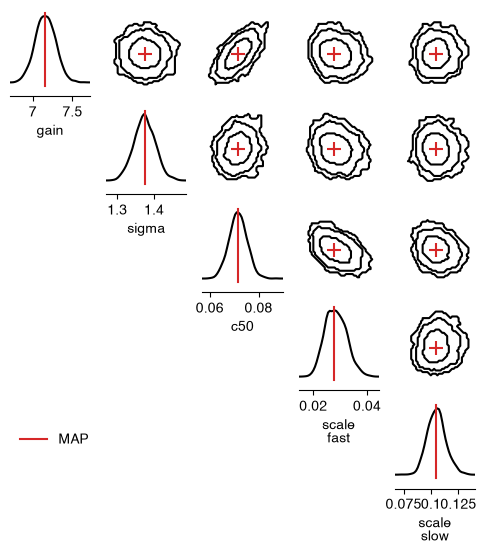

In [14]:
# fitted parameters only: marginals on the diagonal, joint contours above it, MAP estimate in red.
# Diffusion parameters first, then the gate parameters
plot_order = ["gain", "sigma", "c50", "scale_fast", "scale_slow"]

# MAP estimate: the prior is uniform, so it is the parameters of highest likelihood
theta_map, map_log_lik = map_estimate(posterior, fitted, build, stim, contrast, hit, rt)
print("MAP:", {name: round(theta_map[name], 4) for name in plot_order}, f"log-likelihood {map_log_lik:.1f}")

fig = posterior_pairplot(posterior, theta_map, plot_order)

### Posterior predictive

- **Top**: baseline-normalised percent correct and median reaction time of hits, mean ± SD over animals. Model: `N_SIMS` datasets simulated from posterior draws and summarised like the data.
- **Bottom**: reaction times of hits per stimulus and contrast (0% is the catch trials). Line: model density at the posterior mean.

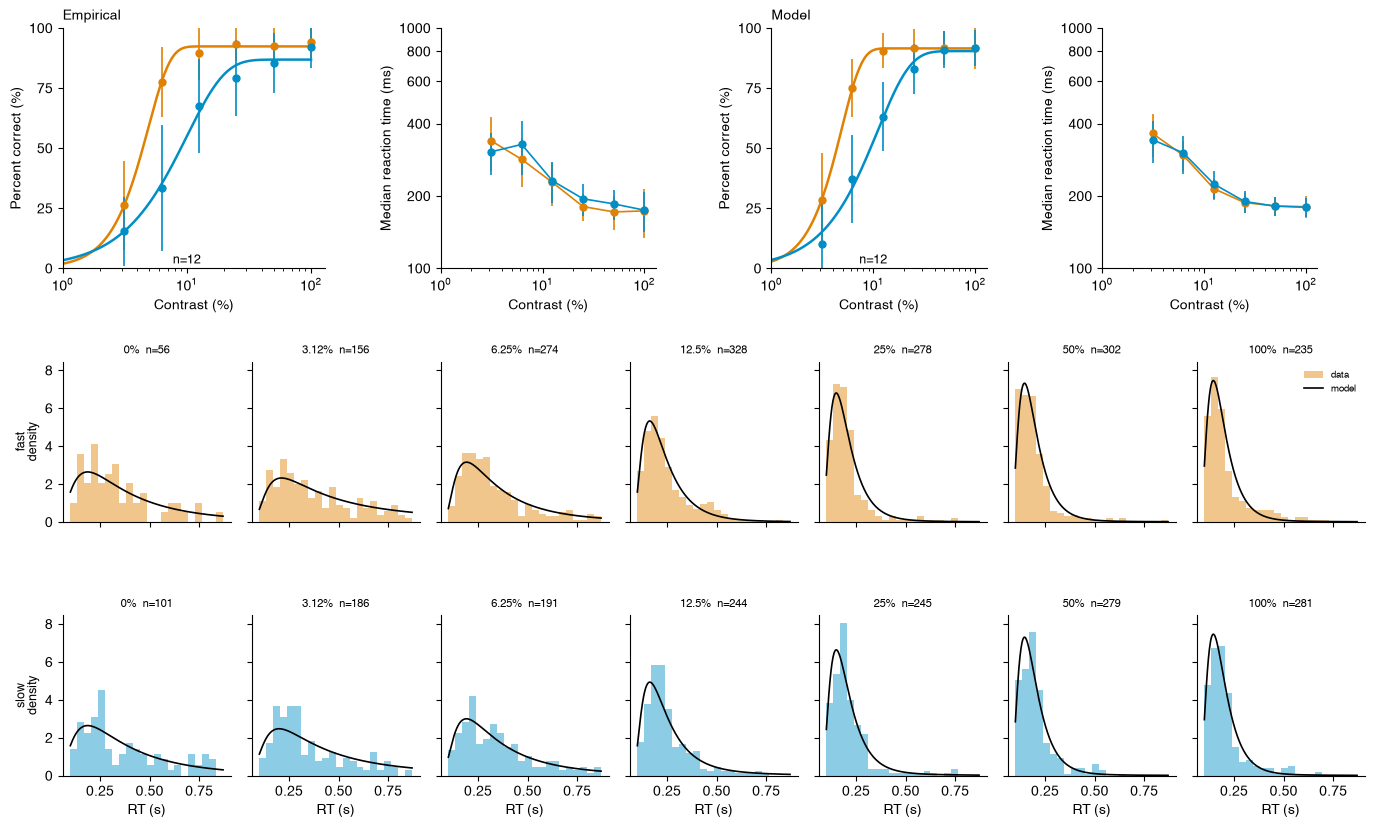

In [15]:
N_SIMS = 200

# posterior draws for the simulations: one simulated dataset per draw
draws = posterior[np.random.choice(len(posterior), N_SIMS, replace=False)]

# the line in the bottom rows is the model at the posterior mean
fig = predictive_figure(trials, build, draws, {"model": (build(posterior_mean), "-")}, palette)

### Gate and drift at the MAP

Dashed lines: the gate `scale` (63% of the ceiling) and `c50` (half-maximal drift). Dots: the tested contrasts.

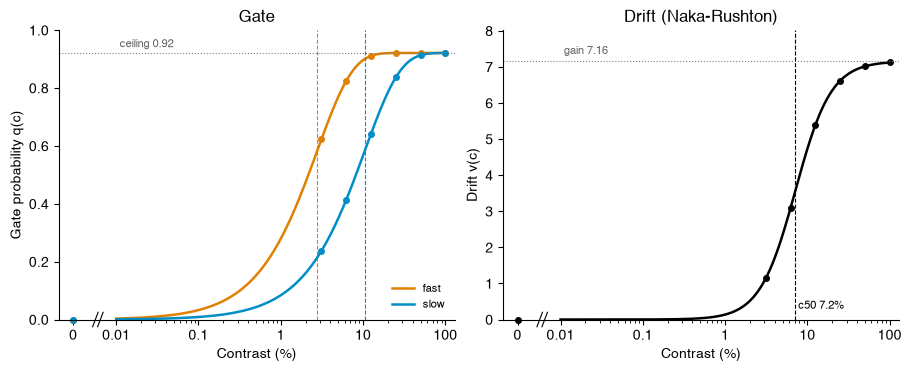

In [16]:
contrasts = np.sort(trials["contrast"].unique().to_numpy())
fig = gate_drift_figure(build(theta_map), contrasts, palette)